# Classification Models Implementation & Comparative Analysis
This notebook demonstrates the implementation of four major classification algorithms:
1. **Support Vector Machine (SVM)**
2. **Decision Tree**
3. **K-Nearest Neighbors (KNN)**
4. **Naïve Bayes**

Each algorithm is evaluated using Accuracy, Precision, Recall, F1-Score, and Log Loss.

In [7]:
# ==============================================================================
# SECTION 1: IMPORTS & DATASET GENERATION
# ==============================================================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, log_loss

# Generate synthetic binary classification dataset
X, y = make_classification(
    n_samples=1000,
    n_features=10,
    n_informative=8,
    n_redundant=2,
    random_state=42
)

# Split into Training and Testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Scale features (Essential for distance-based algorithms like SVM and KNN)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Dictionary to hold evaluation results
results = {}

def evaluate_model(name, model, X_test_data, y_true):
    """Helper function to calculate and store model performance metrics."""
    y_pred = model.predict(X_test_data)

    # Probability predictions for Log Loss
    if hasattr(model, "predict_proba"):
        y_proba = model.predict_proba(X_test_data)
    elif hasattr(model, "decision_function"):
        df = model.decision_function(X_test_data)
        y_proba = 1 / (1 + np.exp(-df))
        y_proba = np.vstack([1 - y_proba, y_proba]).T
    else:
        y_proba = None

    acc = accuracy_score(y_true, y_pred)
    prec = precision_score(y_true, y_pred)
    rec = recall_score(y_true, y_pred)
    f1 = f1_score(y_true, y_pred)
    loss = log_loss(y_true, y_proba) if y_proba is not None else np.nan

    results[name] = {
        'Accuracy': acc,
        'Precision': prec,
        'Recall': rec,
        'F1-Score': f1,
        'Log Loss': loss
    }

    print(f"--- {name} Performance ---")
    print(f"Accuracy : {acc:.4f}")
    print(f"Precision: {prec:.4f}")
    print(f"Recall   : {rec:.4f}")
    print(f"F1-Score : {f1:.4f}")
    print(f"Log Loss : {loss:.4f}\n")

## Support Vector Machine (SVM)

In [8]:
# ==============================================================================
# SECTION 2: SUPPORT VECTOR MACHINE (SVM)
# ==============================================================================
from sklearn.svm import SVC

svm_model = SVC(kernel='rbf', C=1.0, probability=True, random_state=42)
svm_model.fit(X_train_scaled, y_train)

evaluate_model("Support Vector Machine", svm_model, X_test_scaled, y_test)

--- Support Vector Machine Performance ---
Accuracy : 0.9200
Precision: 0.8824
Recall   : 0.9574
F1-Score : 0.9184
Log Loss : 0.2275



## Decision Tree Classifier

In [9]:
# ==============================================================================
# SECTION 3: DECISION TREE
# ==============================================================================
from sklearn.tree import DecisionTreeClassifier

dt_model = DecisionTreeClassifier(max_depth=5, random_state=42)
dt_model.fit(X_train, y_train)  # Decision Trees are scale-invariant

evaluate_model("Decision Tree", dt_model, X_test, y_test)

--- Decision Tree Performance ---
Accuracy : 0.7600
Precision: 0.7300
Recall   : 0.7766
F1-Score : 0.7526
Log Loss : 1.2307



## K-Nearest Neighbors (KNN)

In [10]:
# ==============================================================================
# SECTION 4: K-NEAREST NEIGHBORS (KNN)
# ==============================================================================
from sklearn.neighbors import KNeighborsClassifier

knn_model = KNeighborsClassifier(n_neighbors=5)
knn_model.fit(X_train_scaled, y_train)

evaluate_model("K-Nearest Neighbors", knn_model, X_test_scaled, y_test)

--- K-Nearest Neighbors Performance ---
Accuracy : 0.9100
Precision: 0.8878
Recall   : 0.9255
F1-Score : 0.9062
Log Loss : 0.5622



## Naïve Bayes Classifier

In [11]:
# ==============================================================================
# SECTION 5: NAÏVE BAYES
# ==============================================================================
from sklearn.naive_bayes import GaussianNB

nb_model = GaussianNB()
nb_model.fit(X_train_scaled, y_train)

evaluate_model("Naïve Bayes", nb_model, X_test_scaled, y_test)

--- Naïve Bayes Performance ---
Accuracy : 0.7500
Precision: 0.7075
Recall   : 0.7979
F1-Score : 0.7500
Log Loss : 0.5142



## Comparative Analysis & Visualization

                      COMPARATIVE ANALYSIS SUMMARY                   
                        Accuracy  Precision  Recall  F1-Score  Log Loss
Support Vector Machine      0.92     0.8824  0.9574    0.9184    0.2275
Decision Tree               0.76     0.7300  0.7766    0.7526    1.2307
K-Nearest Neighbors         0.91     0.8878  0.9255    0.9062    0.5622
Naïve Bayes                 0.75     0.7075  0.7979    0.7500    0.5142



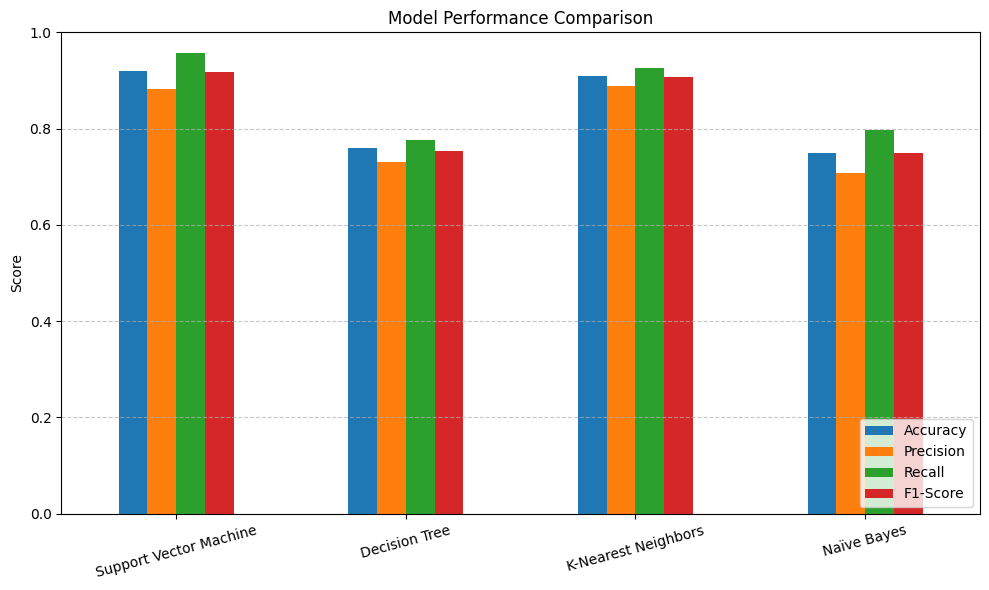

In [12]:
# ==============================================================================
# SECTION 6: COMPARATIVE ANALYSIS & SUMMARY TABLE
# ==============================================================================
df_results = pd.DataFrame(results).T
print("=====================================================================")
print("                      COMPARATIVE ANALYSIS SUMMARY                   ")
print("=====================================================================")
print(df_results.round(4))
print("=====================================================================\n")

# Visualization of metrics comparison
df_results[['Accuracy', 'Precision', 'Recall', 'F1-Score']].plot(kind='bar', figsize=(10, 6))
plt.title('Model Performance Comparison')
plt.ylabel('Score')
plt.ylim(0, 1)
plt.xticks(rotation=15)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()